# 07 · Validação, seleção e previsões finais

**Objetivo:** avaliar os 6 modelos em **treino, validação e teste**, medir a estabilidade em **11 origens de backtest**, diagnosticar resíduos, comparar o Total direto com a soma das máquinas e escolher o modelo de cada série com um critério declarado.

| Camada | Desenho |
|---|---|
| Treino | 01/03/2024 (M2: 08/02/2025) → 09/03/2025; WAPE de ajuste comparado ao piso de ruído |
| Validação | 3 dobras internas de 14 dias (a M2 tem 1) |
| Teste | 10/03 → 23/03/2025, nunca visto no ajuste |
| Backtest | 11 blocos de 14 dias sem sobreposição (21/10/2024 → 23/03/2025), tudo refeito em cada origem; M1 e Total |

Código: `src/validation/` (métricas, backtesting, comparação e seleção). Resultados lidos dos artefatos do pipeline.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

from src.visualization.plots import aplicar_tema
aplicar_tema()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


def mostrar(fig):
    """Exibe a figura uma única vez e libera a memória."""
    display(fig)
    plt.close(fig)

from src.pipeline import carregar_artefato
from src.validation.backtesting import tabela_resultados
from src.visualization.plots import CORES_MODELOS, CORES, cor_serie, formatar_eixo_datas, sombrear_periodo

base = carregar_artefato("base")
principal = carregar_artefato("resultados_principal")["resultados"]
R = {(r.modelo, r.serie, r.alvo): r for r in principal}
MODELOS = ["Naive sazonal", "Média 4 semanas", "Holt-Winters", "SARIMAX", "Poisson/NB2", "Random Forest"]
SERIES = [(s, a) for s in ["Máquina 1", "Máquina 2", "Total"] for a in ["demanda", "receita"]]
tab = tabela_resultados(principal, base)


def painel_modelo(modelo):
    """Previsão × observado no teste para as 6 séries de um modelo, com intervalos de 80% e 95%."""
    fig, eixos = plt.subplots(2, 3, figsize=(18, 7.5))
    for j, serie in enumerate(["Máquina 1", "Máquina 2", "Total"]):
        for i, alvo in enumerate(["demanda", "receita"]):
            ax, r = eixos[i, j], R[(modelo, serie, alvo)]
            y = base.series[(serie, alvo)]
            hist = y.loc[r.origem - pd.Timedelta(days=27):r.origem]
            ax.plot(hist.index, hist.values, color=CORES["contexto"], lw=1.1, label="Treino (28 dias)")
            if r.intervalos is not None:
                ax.fill_between(r.previsao.index, r.intervalos["li_95"], r.intervalos["ls_95"], color=CORES_MODELOS[modelo], alpha=0.13, lw=0, label="IC 95%")
                ax.fill_between(r.previsao.index, r.intervalos["li_80"], r.intervalos["ls_80"], color=CORES_MODELOS[modelo], alpha=0.28, lw=0, label="IC 80%")
            ax.plot(r.previsao.index, y.loc[r.previsao.index], color=CORES["observado"], marker="o", ms=4, lw=1.3, label="Observado")
            ax.plot(r.previsao.index, r.previsao.values, color=CORES_MODELOS[modelo], marker="o", ms=4, lw=2, ls="--", label="Previsto")
            m = tab[(tab["modelo"] == modelo) & (tab["série"] == serie) & (tab["alvo"] == alvo)].iloc[0]
            ax.set_title(f"{serie} — {alvo} · WAPE {m['WAPE_%']:.0f}% · viés {m['ME_relativo_%']:+.0f}%", fontsize=11)
            ax.set_ylim(bottom=0)
            formatar_eixo_datas(ax, curto=True)
    eixos[0, 0].legend(loc="upper left", fontsize=8, ncol=2)
    fig.suptitle(f"{modelo}: previsão de 14 dias a partir de 09/03/2025 (teste 10–23/03/2025)")
    fig.tight_layout()
    return fig


def especificacoes(modelo):
    return pd.DataFrame([{"série": s, "alvo": a, "especificação": R[(modelo, s, a)].especificacao,
                          "início do treino": f"{R[(modelo, s, a)].inicio_treino:%d/%m/%Y}",
                          "MAE validação": R[(modelo, s, a)].mae_validacao, "tempo (s)": R[(modelo, s, a)].tempo_s}
                         for s, a in SERIES if (modelo, s, a) in R])

from src.validation import model_comparison as mc

av = carregar_artefato("avaliacao")
finais = carregar_artefato("previsoes_finais")

## 1. Treino × validação × teste

,série,alvo,modelo,treino: WAPE ajuste % (28 d),piso de ruído %,validação: MAE,teste: MAE,validação: WAPE %,teste: WAPE %,backtest: MASE médio,backtest: WAPE médio %
0,Máquina 1,demanda,Naive sazonal,18.800,20.660,4.600,3.500,33.100,24.140,1.010,52.230
1,Máquina 1,demanda,Média 4 semanas,24.400,20.660,4.550,3.180,32.760,21.920,0.850,42.500
2,Máquina 1,demanda,Holt-Winters,12.280,20.660,3.750,3.240,27.020,22.350,0.770,38.370
3,Máquina 1,demanda,SARIMAX,14.390,20.660,4.560,3.330,32.850,22.930,0.980,44.790
4,Máquina 1,demanda,Poisson/NB2,11.470,20.660,4.870,3.490,35.070,24.060,0.890,42.730
5,Máquina 1,demanda,Random Forest,32.810,20.660,5.080,3.870,36.600,26.690,0.820,39.290
6,Máquina 1,receita,Naive sazonal,21.320,20.930,150.330,103.460,34.690,22.780,1.020,52.360
7,Máquina 1,receita,Média 4 semanas,24.740,20.930,146.120,93.890,33.720,20.680,0.860,42.710
8,Máquina 1,receita,Holt-Winters,15.530,20.930,127.210,92.730,29.350,20.420,0.820,40.170
9,Máquina 1,receita,SARIMAX,18.630,20.930,148.290,99.110,34.220,21.830,1.010,47.210


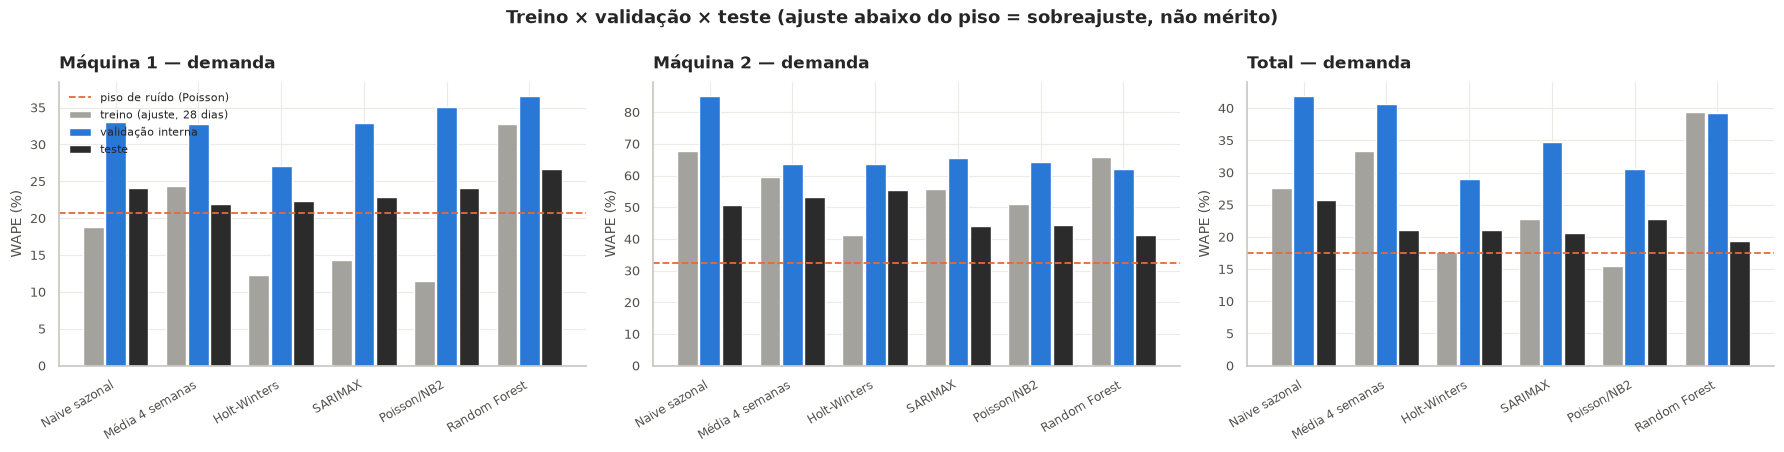

In [2]:
display(av['tvt'].round(2))
mostrar(mc.grafico_treino_validacao_teste(av['tvt']))

**Leitura (generalização):**
- **Estatísticos em janelas curtas:** o WAPE de ajuste no treino fica **abaixo do piso de ruído** (~21% nos últimos 28 dias da M1). É otimismo, porque o ajuste é calculado nos mesmos dias usados na estimação.
- **Random Forest:** o ajuste é honesto, fora da amostra, e fica acima do piso.
- **Validação × teste:** os WAPEs de validação são maiores que os de teste, porque as dobras internas (27/01–09/03) atravessam a quebra de 2025 e o teste cai num regime já estabelecido. A ordem dos modelos não se mantém de forma estável entre validação e teste.

Por isso nenhum dos dois é usado sozinho: o **backtest em 11 origens** é a medida principal de estabilidade.

## 2. Desempenho no teste

,modelo,série,alvo,MAE,RMSE,WAPE_%,MAPE_%,ME,ME_relativo_%,MASE,cobertura_80_%,cobertura_95_%,winkler_95
0,Média 4 semanas,Máquina 1,demanda,3.180,3.710,21.920,24.320,0.320,2.220,0.690,92.860,100.000,19.230
1,Holt-Winters,Máquina 1,demanda,3.240,4.120,22.350,25.360,1.160,8.030,0.700,92.860,100.000,19.960
2,SARIMAX,Máquina 1,demanda,3.330,3.730,22.930,26.820,0.260,1.760,0.720,78.570,92.860,15.830
3,Poisson/NB2,Máquina 1,demanda,3.490,4.160,24.060,26.050,0.150,1.030,0.760,78.570,100.000,14.570
4,Naive sazonal,Máquina 1,demanda,3.500,4.330,24.140,26.490,0.070,0.490,0.760,100.000,100.000,25.990
5,Random Forest,Máquina 1,demanda,3.870,4.470,26.690,32.180,-0.850,-5.840,0.840,92.860,100.000,24.020
6,Holt-Winters,Máquina 1,receita,92.730,111.680,20.420,21.840,-16.770,-3.690,0.630,85.710,100.000,562.750
7,Média 4 semanas,Máquina 1,receita,93.890,115.960,20.680,22.250,7.290,1.610,0.630,92.860,100.000,608.430
8,SARIMAX,Máquina 1,receita,99.110,124.040,21.830,23.270,8.600,1.890,0.670,71.430,92.860,679.830
9,Poisson/NB2,Máquina 1,receita,100.230,123.760,22.070,23.410,1.820,0.400,0.680,78.570,92.860,506.650


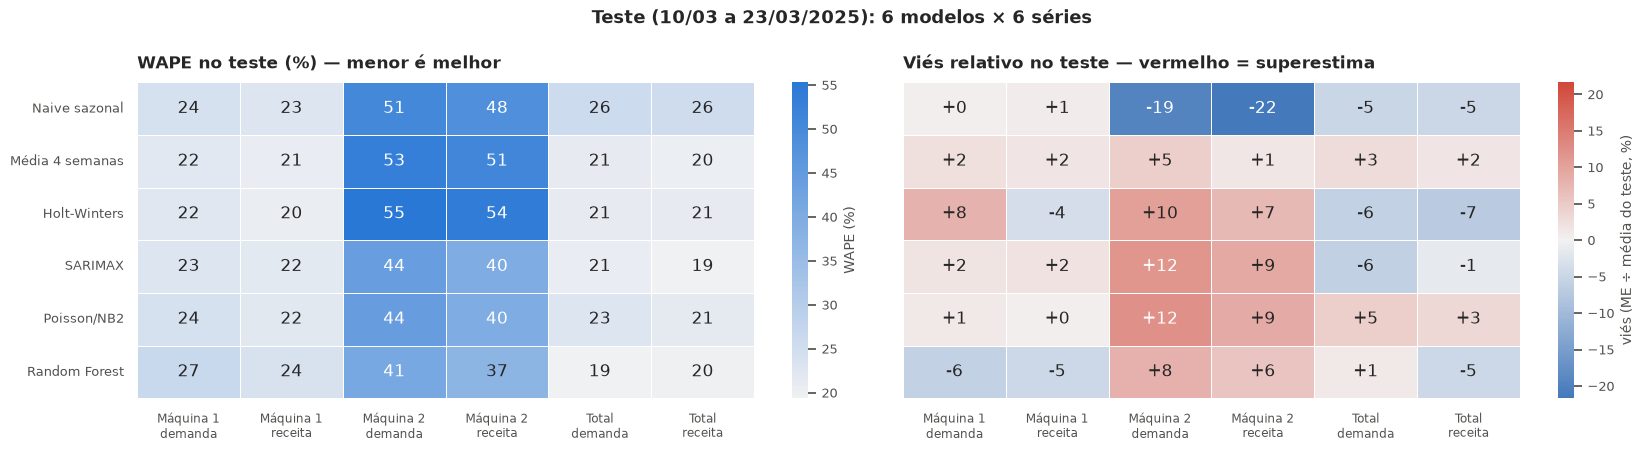

**Diebold-Mariano (HLN) contra o naive sazonal, com Holm por série** — 14 erros de uma única trajetória: baixo poder

conclusão (5%)     indistinguível
série     alvo                   
Máquina 1 demanda               5
          receita               5
Máquina 2 demanda               5
          receita               5
Total     demanda               5
          receita               5

In [3]:
cols = ["modelo", "série", "alvo", "MAE", "RMSE", "WAPE_%", "MAPE_%", "ME", "ME_relativo_%", "MASE", "cobertura_80_%", "cobertura_95_%", "winkler_95"]
display(av["tab_teste"][cols].sort_values(["série", "alvo", "MAE"]).round(2).reset_index(drop=True))
mostrar(mc.grafico_heatmap_teste(av["tab_teste"]))
display(Markdown("**Diebold-Mariano (HLN) contra o naive sazonal, com Holm por série** — 14 erros de uma única trajetória: baixo poder"))
display(av["dm"].groupby(["série", "alvo", "conclusão (5%)"]).size().unstack(fill_value=0))

**Leitura:**
- No teste, os WAPEs ficam em **~20–23% na M1 e no Total** e **~37–55% na M2**, perto dos pisos de ruído.
- Com 14 dias, **nenhuma diferença é estatisticamente distinguível** do naive (0 de 30 comparações de Diebold-Mariano com Holm). Uma única janela de teste não basta para ranquear modelos.
- **Viés:** os modelos de nível local subestimam levemente o Total. A cobertura dos intervalos varia de 64% a 100% entre os modelos.

## 3. Backtest em 11 origens: estabilidade e significância

,série,alvo,modelo,MASE médio,MAE médio,WAPE médio %,ME médio,posto médio,DP do posto,vence naive (% origens),vence média 4 sem. (% origens),p Holm vs naive,p Holm vs média 4 sem.
0,Máquina 1,demanda,Holt-Winters,0.765,3.635,38.375,0.348,2.636,1.286,81.818,72.727,0.074,0.078
1,Máquina 1,demanda,Random Forest,0.820,3.891,39.292,-0.487,2.909,1.868,72.727,54.545,0.313,1.000
2,Máquina 1,demanda,Média 4 semanas,0.854,4.062,42.502,-0.094,3.545,1.916,81.818,NaN,0.340,NaN
3,Máquina 1,demanda,Poisson/NB2,0.895,4.249,42.735,-0.231,3.636,1.362,72.727,54.545,0.774,1.000
4,Máquina 1,demanda,SARIMAX,0.977,4.635,44.787,0.694,3.364,1.433,81.818,54.545,0.869,1.000
5,Máquina 1,demanda,Naive sazonal,1.008,4.792,52.229,0.156,4.909,1.758,NaN,18.182,NaN,0.454
6,Máquina 1,receita,Random Forest,0.787,118.998,37.776,-11.873,2.364,1.690,72.727,72.727,0.103,0.895
7,Máquina 1,receita,Holt-Winters,0.823,124.538,40.167,-4.076,2.909,1.446,81.818,63.636,0.321,1.000
8,Máquina 1,receita,Média 4 semanas,0.865,130.933,42.708,-1.047,3.636,1.859,81.818,NaN,0.321,NaN
9,Máquina 1,receita,Poisson/NB2,0.892,134.932,42.544,-5.467,3.364,1.286,72.727,54.545,0.600,1.000


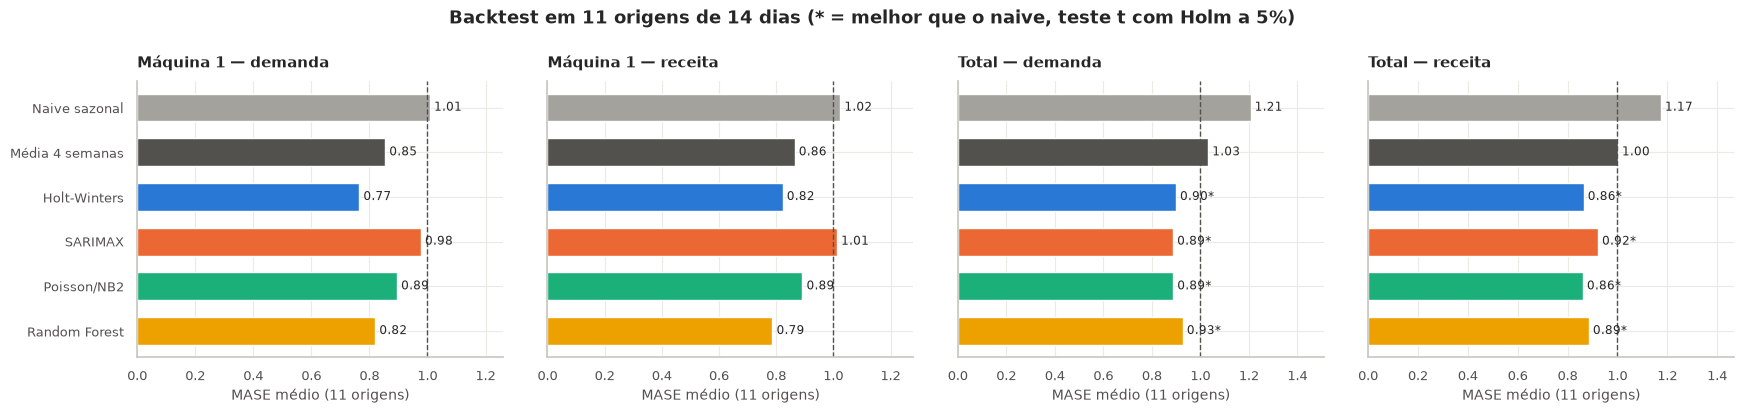

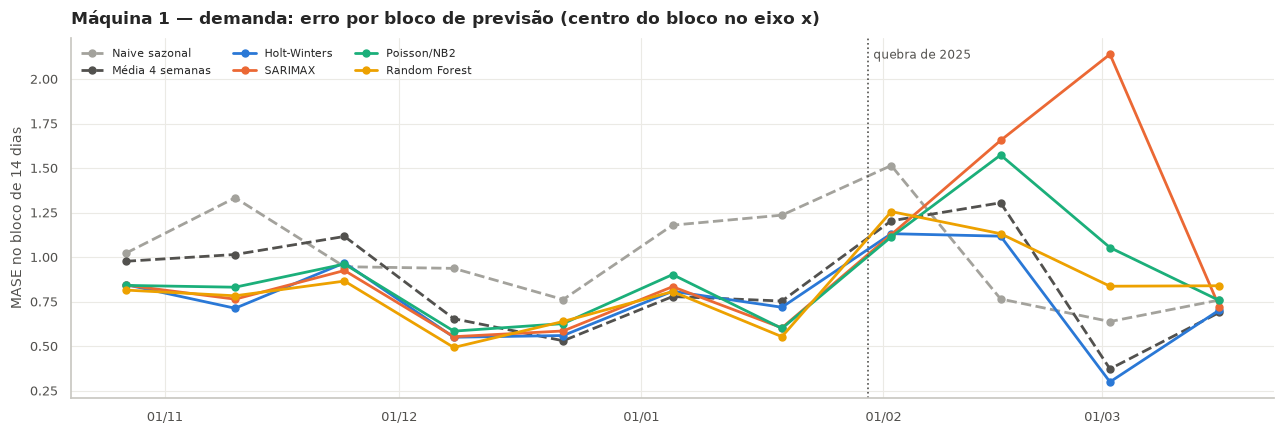

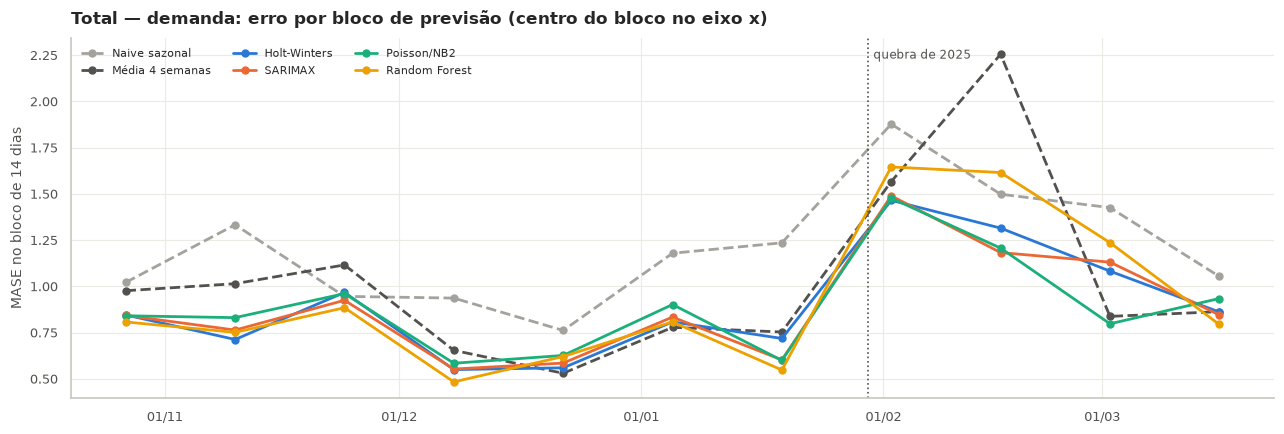

In [4]:
cols = ["série", "alvo", "modelo", "MASE médio", "MAE médio", "WAPE médio %", "ME médio", "posto médio", "DP do posto",
        "vence naive (% origens)", "vence média 4 sem. (% origens)", "p Holm vs naive", "p Holm vs média 4 sem."]
display(av["resumo_bt"][cols].round(3))
mostrar(mc.grafico_backtest(av["resumo_bt"]))
for s, a in [("Máquina 1", "demanda"), ("Total", "demanda")]:
    mostrar(mc.grafico_backtest_origens(av["bt"], s, a))

**Leitura:**
- **O naive sazonal é o pior modelo** nas 4 séries (MASE 1,01–1,21).
- **Máquina 1:** Holt-Winters tem o melhor MASE na demanda (0,77, ~24% abaixo do naive), seguido da Random Forest (0,82). Na receita, lideram Random Forest (0,79) e Holt-Winters (0,82). **Nenhuma diferença sobrevive à correção de Holm** (menor p = 0,07): com 11 blocos e o ruído de contagem, ganhos de ~20% ainda não se distinguem do acaso.
- **Total:** **os 4 candidatos são significativamente melhores que o naive** (p Holm ≤ 0,005). A Média 4 semanas não é.
- **Contra a Média 4 semanas**, nenhum candidato é significativamente melhor. Os candidatos a vencem em 55–73% das origens: a vantagem é consistente, mas pequena.

## 4. Erro por período: capacidade de capturar mudanças de comportamento

In [5]:
display(av['bt'].pipe(mc.erros_por_periodo).round(2))

período                            origens antes da quebra de 2025  origens em torno/depois da quebra de 2025
série     alvo    modelo                                                                                     
Máquina 1 demanda Holt-Winters                               0.740                                      0.810
                  Média 4 semanas                            0.830                                      0.890
                  Naive sazonal                              1.060                                      0.920
                  Poisson/NB2                                0.760                                      1.120
                  Random Forest                              0.710                                      1.020
                  SARIMAX                                    0.730                                      1.410
          receita Holt-Winters                               0.760                                      0.940
                  Média 4 semanas                            0.850                                      0.880
                  Naive sazonal                              1.080                                      0.920
                  Poisson/NB2                                0.780                                      1.090
                  Random Forest                              0.700                                      0.930
                  SARIMAX                                    0.810                                      1.370
Total     demanda Holt-Winters                               0.740                                      1.180
                  Média 4 semanas                            0.830                                      1.380
                  Naive sazonal                              1.060                                      1.460
                  Poisson/NB2                                0.760                                      1.100
                  Random Forest                              0.700                                      1.320
                  SARIMAX                                    0.730                                      1.160
          receita Holt-Winters                               0.760                                      1.050
                  Média 4 semanas                            0.850                                      1.260
                  Naive sazonal                              1.080                                      1.330
                  Poisson/NB2                                0.780                                      1.010
                  Random Forest                              0.700                                      1.210
                  SARIMAX                                    0.810                                      1.120

**Leitura:** **todos os modelos pioram nas origens em torno da quebra de 2025.** O SARIMAX é o mais afetado na M1: MASE de 0,73 → 1,41. O Holt-Winters é o mais robusto (0,74 → 0,81), porque o nível exponencial se adapta sozinho.

Antes da quebra, a Random Forest é a melhor (0,70–0,71), mas reage com atraso ao novo patamar, porque as árvores não extrapolam.

Em produção, isso reforça dois pontos: **detectar quebras cedo** e **preferir modelos de nível adaptativo** em séries sujeitas a mudanças operacionais.

## 5. Diagnóstico de resíduos

,série,alvo,modelo,n resíduos,média dos resíduos,Ljung-Box p (treino),Shapiro p (treino),Kruskal p (resíduo × dia da semana),Ljung-Box p (erros de teste),viés no teste (obs − prev),t p (viés no teste = 0)
0,Máquina 1,demanda,Naive sazonal,360,0.103,0.000,0.070,1.000,0.069,-0.071,0.954
1,Máquina 1,demanda,Média 4 semanas,360,0.315,0.000,0.000,0.930,0.728,-0.321,0.759
2,Máquina 1,demanda,Holt-Winters,49,0.418,0.581,0.615,0.992,0.420,-1.165,0.307
3,Máquina 1,demanda,SARIMAX,49,-0.193,0.759,0.093,0.068,0.323,-0.256,0.808
4,Máquina 1,demanda,Poisson/NB2,32,0.084,0.941,0.002,0.818,0.451,-0.149,0.899
5,Máquina 1,demanda,Random Forest,339,0.196,0.000,0.000,0.198,0.350,0.847,0.498
6,Máquina 1,receita,Naive sazonal,360,2.968,0.000,0.447,1.000,0.219,-3.254,0.933
7,Máquina 1,receita,Média 4 semanas,360,8.749,0.000,0.000,0.937,0.761,-7.294,0.824
8,Máquina 1,receita,Holt-Winters,49,11.240,0.663,0.847,0.997,0.447,16.772,0.593
9,Máquina 1,receita,SARIMAX,32,7.417,0.851,0.280,0.136,0.710,-8.596,0.806


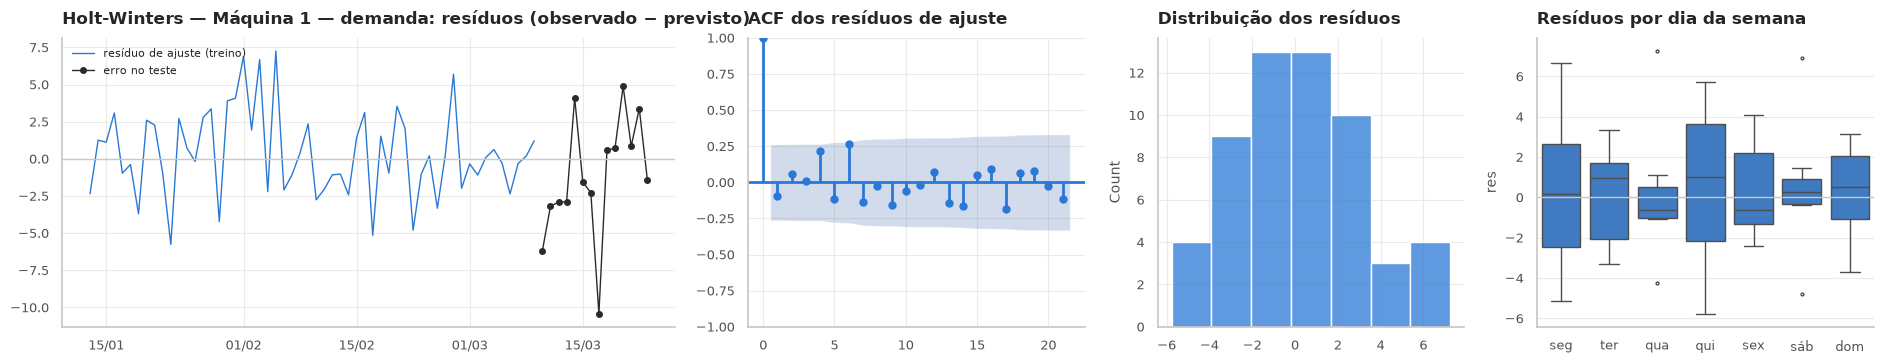

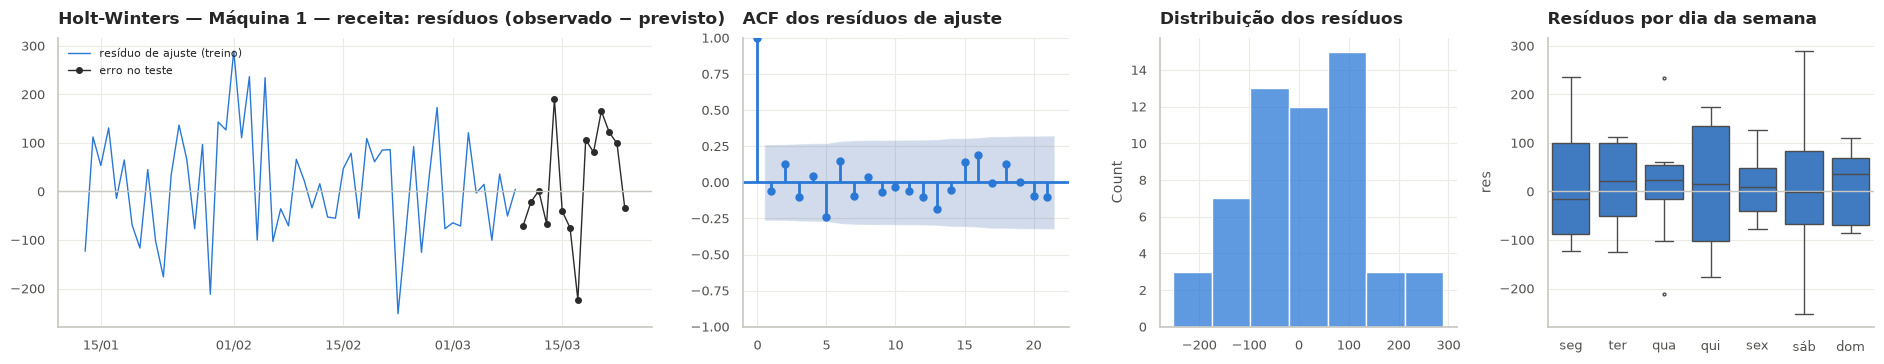

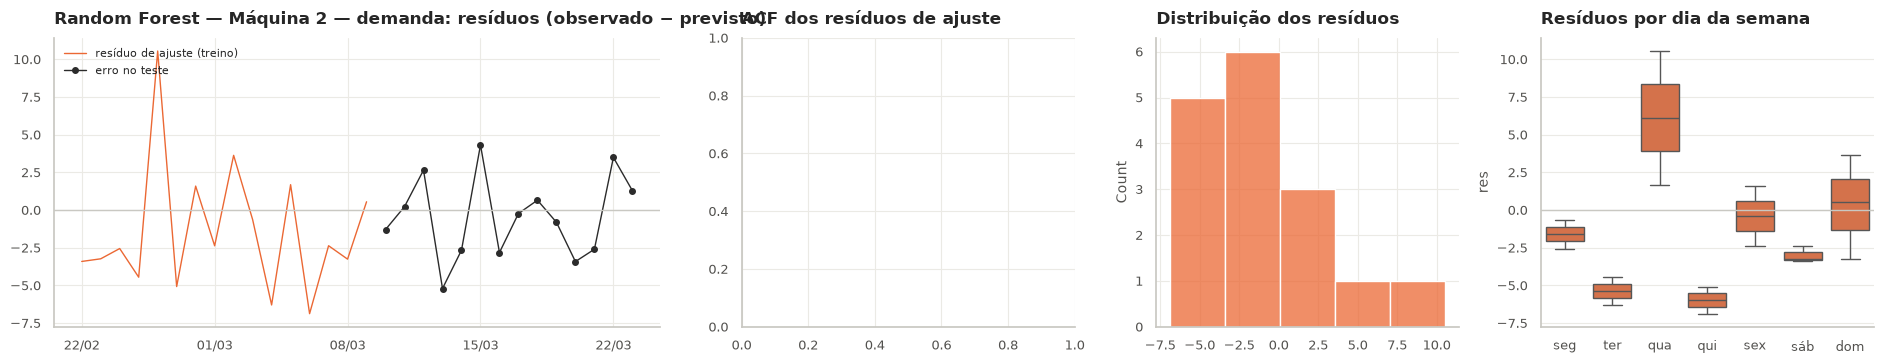

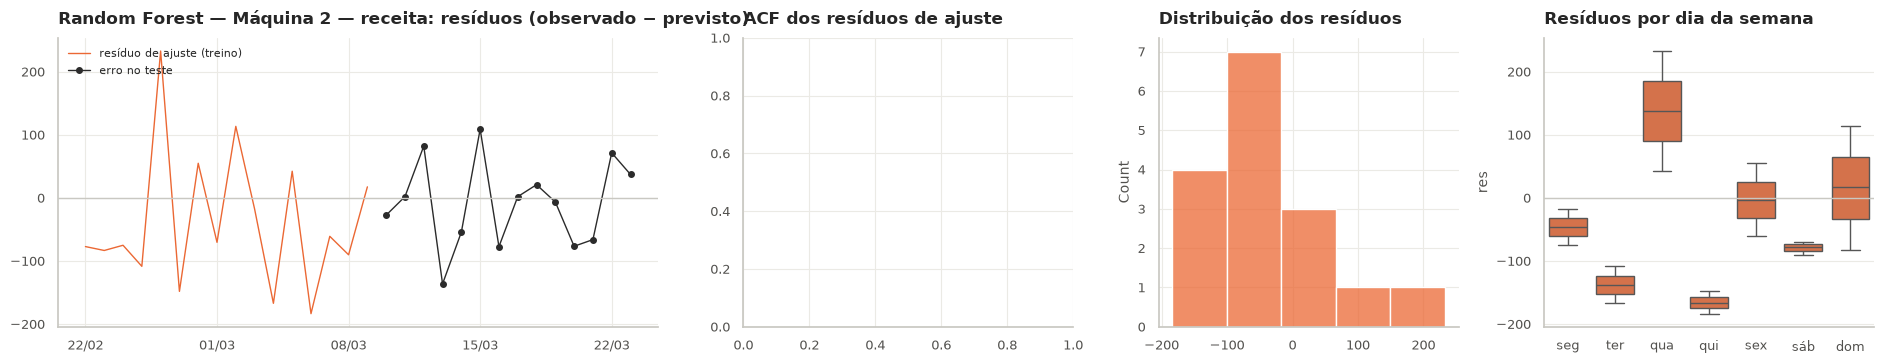

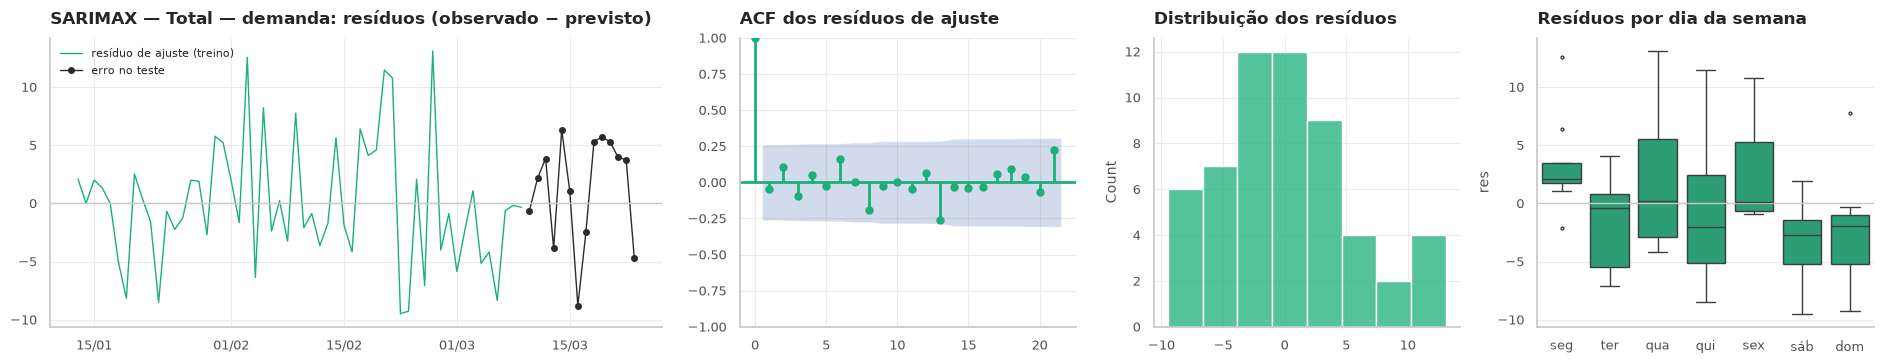

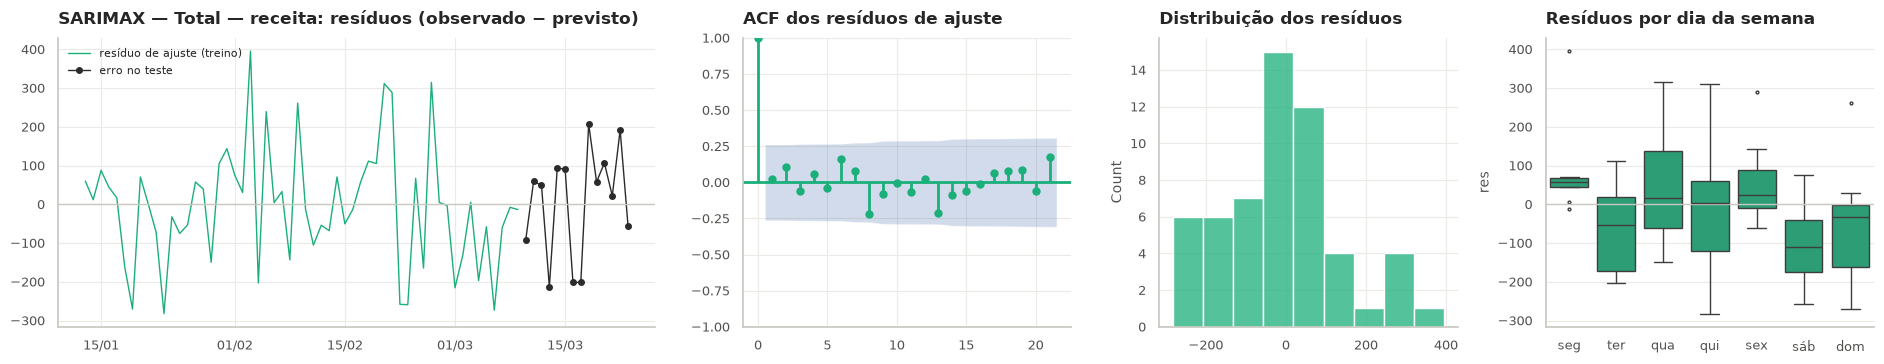

In [6]:
display(av["residuos"].round(3))
idx = {(r.modelo, r.serie, r.alvo): r for r in principal}
for _, e in av["selecao"][av["selecao"]["escolhido"]].iterrows():
    mostrar(mc.grafico_residuos(idx[(e["modelo"], e["série"], e["alvo"])], base))

**Leitura:**
- **Nos modelos escolhidos**, os resíduos de ajuste:
  - não mostram autocorrelação (Ljung-Box p = 0,58 no Holt-Winters da M1 e 0,68–0,74 no SARIMAX do Total);
  - não têm padrão por dia da semana (Kruskal p ≥ 0,10): o padrão semanal foi capturado;
  - não rejeitam a normalidade (Shapiro p ≥ 0,10), mas as amostras são curtas (49 dias, por causa da janela de 8 semanas).
- **Nos modelos com resíduos do treino inteiro** (baselines e Random Forest), o Ljung-Box rejeita: a autocorrelação vem das **mudanças de nível** que esses resíduos atravessam. É mais uma evidência a favor das janelas recentes e das dummies.
- **O viés dos erros de teste não é significativamente diferente de zero** em nenhum modelo (teste t, p ≥ 0,22).
- Na M2, a Random Forest tem só 9 resíduos fora da amostra: não há diagnóstico possível. Os intervalos são avaliados pela **cobertura empírica**, e não por suposição gaussiana.

## 6. Total: modelo independente × soma das previsões das máquinas

,modelo,alvo,MAE Total direto,MAE soma M1 + M2,ME Total direto,ME soma M1 + M2,soma melhor?,variação % (soma vs direto)
0,Naive sazonal,demanda,5.140,5.140,-1.000,-1.000,False,0.000
1,Média 4 semanas,demanda,4.210,4.210,0.570,0.570,False,0.000
2,Holt-Winters,demanda,4.210,4.570,-1.160,1.740,False,8.680
3,SARIMAX,demanda,4.130,3.730,-1.210,0.900,True,-9.700
4,Poisson/NB2,demanda,4.560,4.030,0.910,0.820,True,-11.650
5,Random Forest,demanda,3.880,4.090,0.220,-0.390,False,5.570
6,Naive sazonal,receita,153.670,153.670,-28.670,-28.670,False,0.000
7,Média 4 semanas,receita,122.420,122.420,9.470,9.470,False,0.000
8,Holt-Winters,receita,126.310,119.890,-41.410,-6.070,True,-5.080
9,SARIMAX,receita,117.090,115.770,-8.230,22.160,True,-1.130


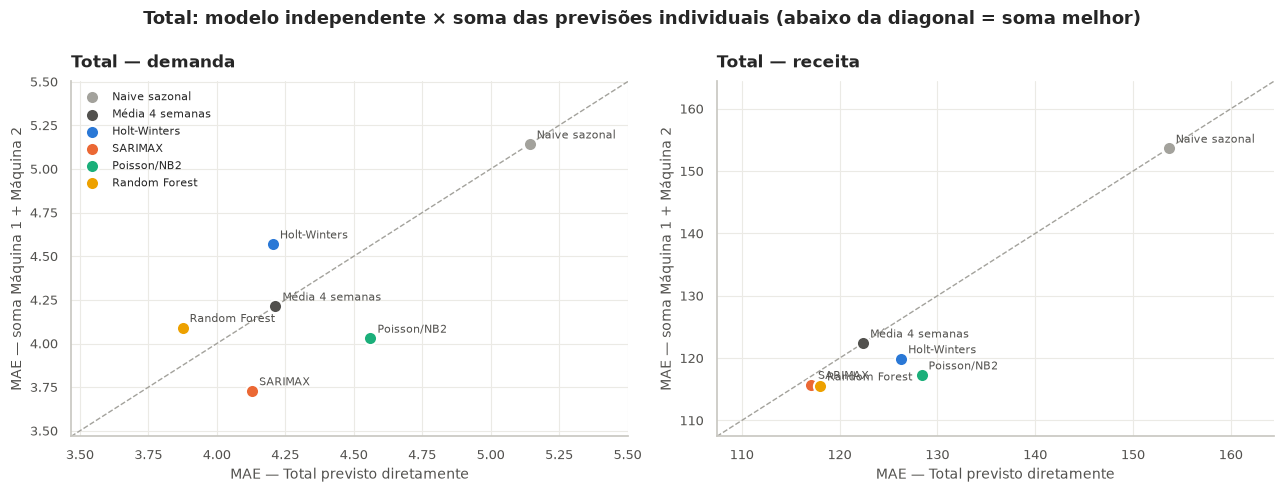

**Modelos escolhidos: Total direto × soma (escolhido da M1 + escolhido da M2)**

,alvo,abordagem,MAE,RMSE,MAPE_%,sMAPE_%,WAPE_%,R2,ME,ME_relativo_%,MASE
0,demanda,Total direto,4.130,4.620,24.150,22.360,20.650,0.220,-1.210,-6.050,0.850
1,demanda,Soma M1 + M2,3.590,4.880,22.030,19.010,17.950,0.130,1.620,8.100,0.740
2,demanda,diferença média futura (direto − soma),NaN,NaN,NaN,NaN,NaN,NaN,0.770,NaN,NaN
3,receita,Total direto,117.090,135.090,23.570,21.760,19.470,0.280,-8.230,-1.370,0.760
4,receita,Soma M1 + M2,107.330,124.050,20.640,19.110,17.840,0.390,-8.280,-1.380,0.700
5,receita,diferença média futura (direto − soma),NaN,NaN,NaN,NaN,NaN,NaN,-53.070,NaN,NaN


In [7]:
display(av["bottom_up"].round(2))
mostrar(mc.grafico_bottom_up(av["bottom_up"]))
display(Markdown("**Modelos escolhidos: Total direto × soma (escolhido da M1 + escolhido da M2)**"))
display(finais["comparacao_total"].round(2))

**Leitura:**
- **Mesmo modelo nas duas abordagens:**
  - na **receita**, a soma das máquinas erra menos nos 4 candidatos (−1% a −9%);
  - na **demanda**, em 2 de 4 (SARIMAX e Poisson; o Holt-Winters e a RF pioram).
- **Modelos escolhidos:** a soma (Holt-Winters M1 + RF M2) erra **13% menos na demanda e 8% menos na receita** que o SARIMAX do Total. É uma única janela de 14 dias, sem backtest possível, porque a M2 só existe a partir de fev/2025.
- **Por que a soma ajuda:** o modelo direto precisa "aprender" a entrada da M2 por `maquinas_ativas` com 4–5 semanas de dados. A soma herda a estrutura de cada máquina.
- **No futuro, as abordagens divergem na receita:** o Total direto prevê ~53 u.m./dia a menos que a soma. Essa divergência é exatamente o que um monitor de coerência deve acompanhar.
- **Recomendação:**
  - manter o **Total direto como modelo independente** (exigência do problema e referência quando as máquinas mudarem);
  - usar a **soma como verificação de coerência** e, para o planejamento consolidado, considerar a soma enquanto a M2 tiver pouco histórico;
  - como evolução, a **reconciliação hierárquica (MinT)** combina as duas de forma ótima.

## 7. Seleção final

`escore = 0,40·posto(teste) + 0,35·posto(backtest) + 0,25·posto(estabilidade)`, com filtro de viés |ME| / média ≤ 15%. Na M2, sem backtest possível, os componentes são validação interna e |viés|. O **teste tem peso importante**, como pede o enunciado, mas não decide sozinho.

In [8]:
display(av['selecao'].round(2).reset_index(drop=True))

,série,alvo,modelo,MAE,WAPE_%,viés relativo %,posto teste,posto backtest,posto estabilidade,escore,passa filtro de viés,escolhido,base do escore
0,Máquina 1,demanda,Holt-Winters,3.240,22.350,8.030,2.000,1.000,1.000,1.400,True,True,teste + backtest (11 origens) + estabilidade
1,Máquina 1,demanda,Média 4 semanas,3.180,21.920,2.220,1.000,3.000,5.000,2.700,True,False,teste + backtest (11 origens) + estabilidade
2,Máquina 1,demanda,SARIMAX,3.330,22.930,1.760,3.000,5.000,2.000,3.450,True,False,teste + backtest (11 origens) + estabilidade
3,Máquina 1,demanda,Poisson/NB2,3.490,24.060,1.030,4.000,4.000,2.000,3.500,True,False,teste + backtest (11 origens) + estabilidade
4,Máquina 1,demanda,Random Forest,3.870,26.690,-5.840,6.000,2.000,2.000,3.600,True,False,teste + backtest (11 origens) + estabilidade
5,Máquina 1,demanda,Naive sazonal,3.500,24.140,0.490,5.000,6.000,6.000,5.600,True,False,teste + backtest (11 origens) + estabilidade
6,Máquina 1,receita,Holt-Winters,92.730,20.420,-3.690,1.000,2.000,2.000,1.600,True,True,teste + backtest (11 origens) + estabilidade
7,Máquina 1,receita,Random Forest,107.980,23.780,-4.690,6.000,1.000,1.000,3.000,True,False,teste + backtest (11 origens) + estabilidade
8,Máquina 1,receita,Média 4 semanas,93.890,20.680,1.610,2.000,3.000,5.000,3.100,True,False,teste + backtest (11 origens) + estabilidade
9,Máquina 1,receita,SARIMAX,99.110,21.830,1.890,3.000,5.000,3.000,3.700,True,False,teste + backtest (11 origens) + estabilidade


| Série | Escolhido | Por quê |
|---|---|---|
| Máquina 1 (demanda e receita) | **Holt-Winters** | melhor no backtest na demanda e 1º no teste na receita; o mais robusto à quebra de 2025; simples e barato |
| Máquina 2 (demanda e receita) | **Random Forest regularizada** | 1ª no teste nos dois alvos e 1ª/2ª na validação; com 30 dias, a regra de 1 EP produz uma previsão quase plana, adequada a uma série sem estrutura estimável |
| Total (demanda e receita) | **SARIMAX** | 1º no backtest e 2º no teste na demanda; 1º no teste na receita; incorpora `maquinas_ativas` e `dummy_novos_clientes` |

**Ressalva:** como o teste entra na escolha, o erro de teste do escolhido é otimista. O MASE do backtest é a estimativa de desempenho esperado.

## 8. Previsões finais (24/03 → 06/04/2025)

Os modelos escolhidos são reestimados com todos os dados até 23/03/2025. As previsões, métricas e gráficos ficam em `reports/forecasts/{machine_1, machine_2, total}/`, e os modelos versionados, em `models/`.

**machine_1**

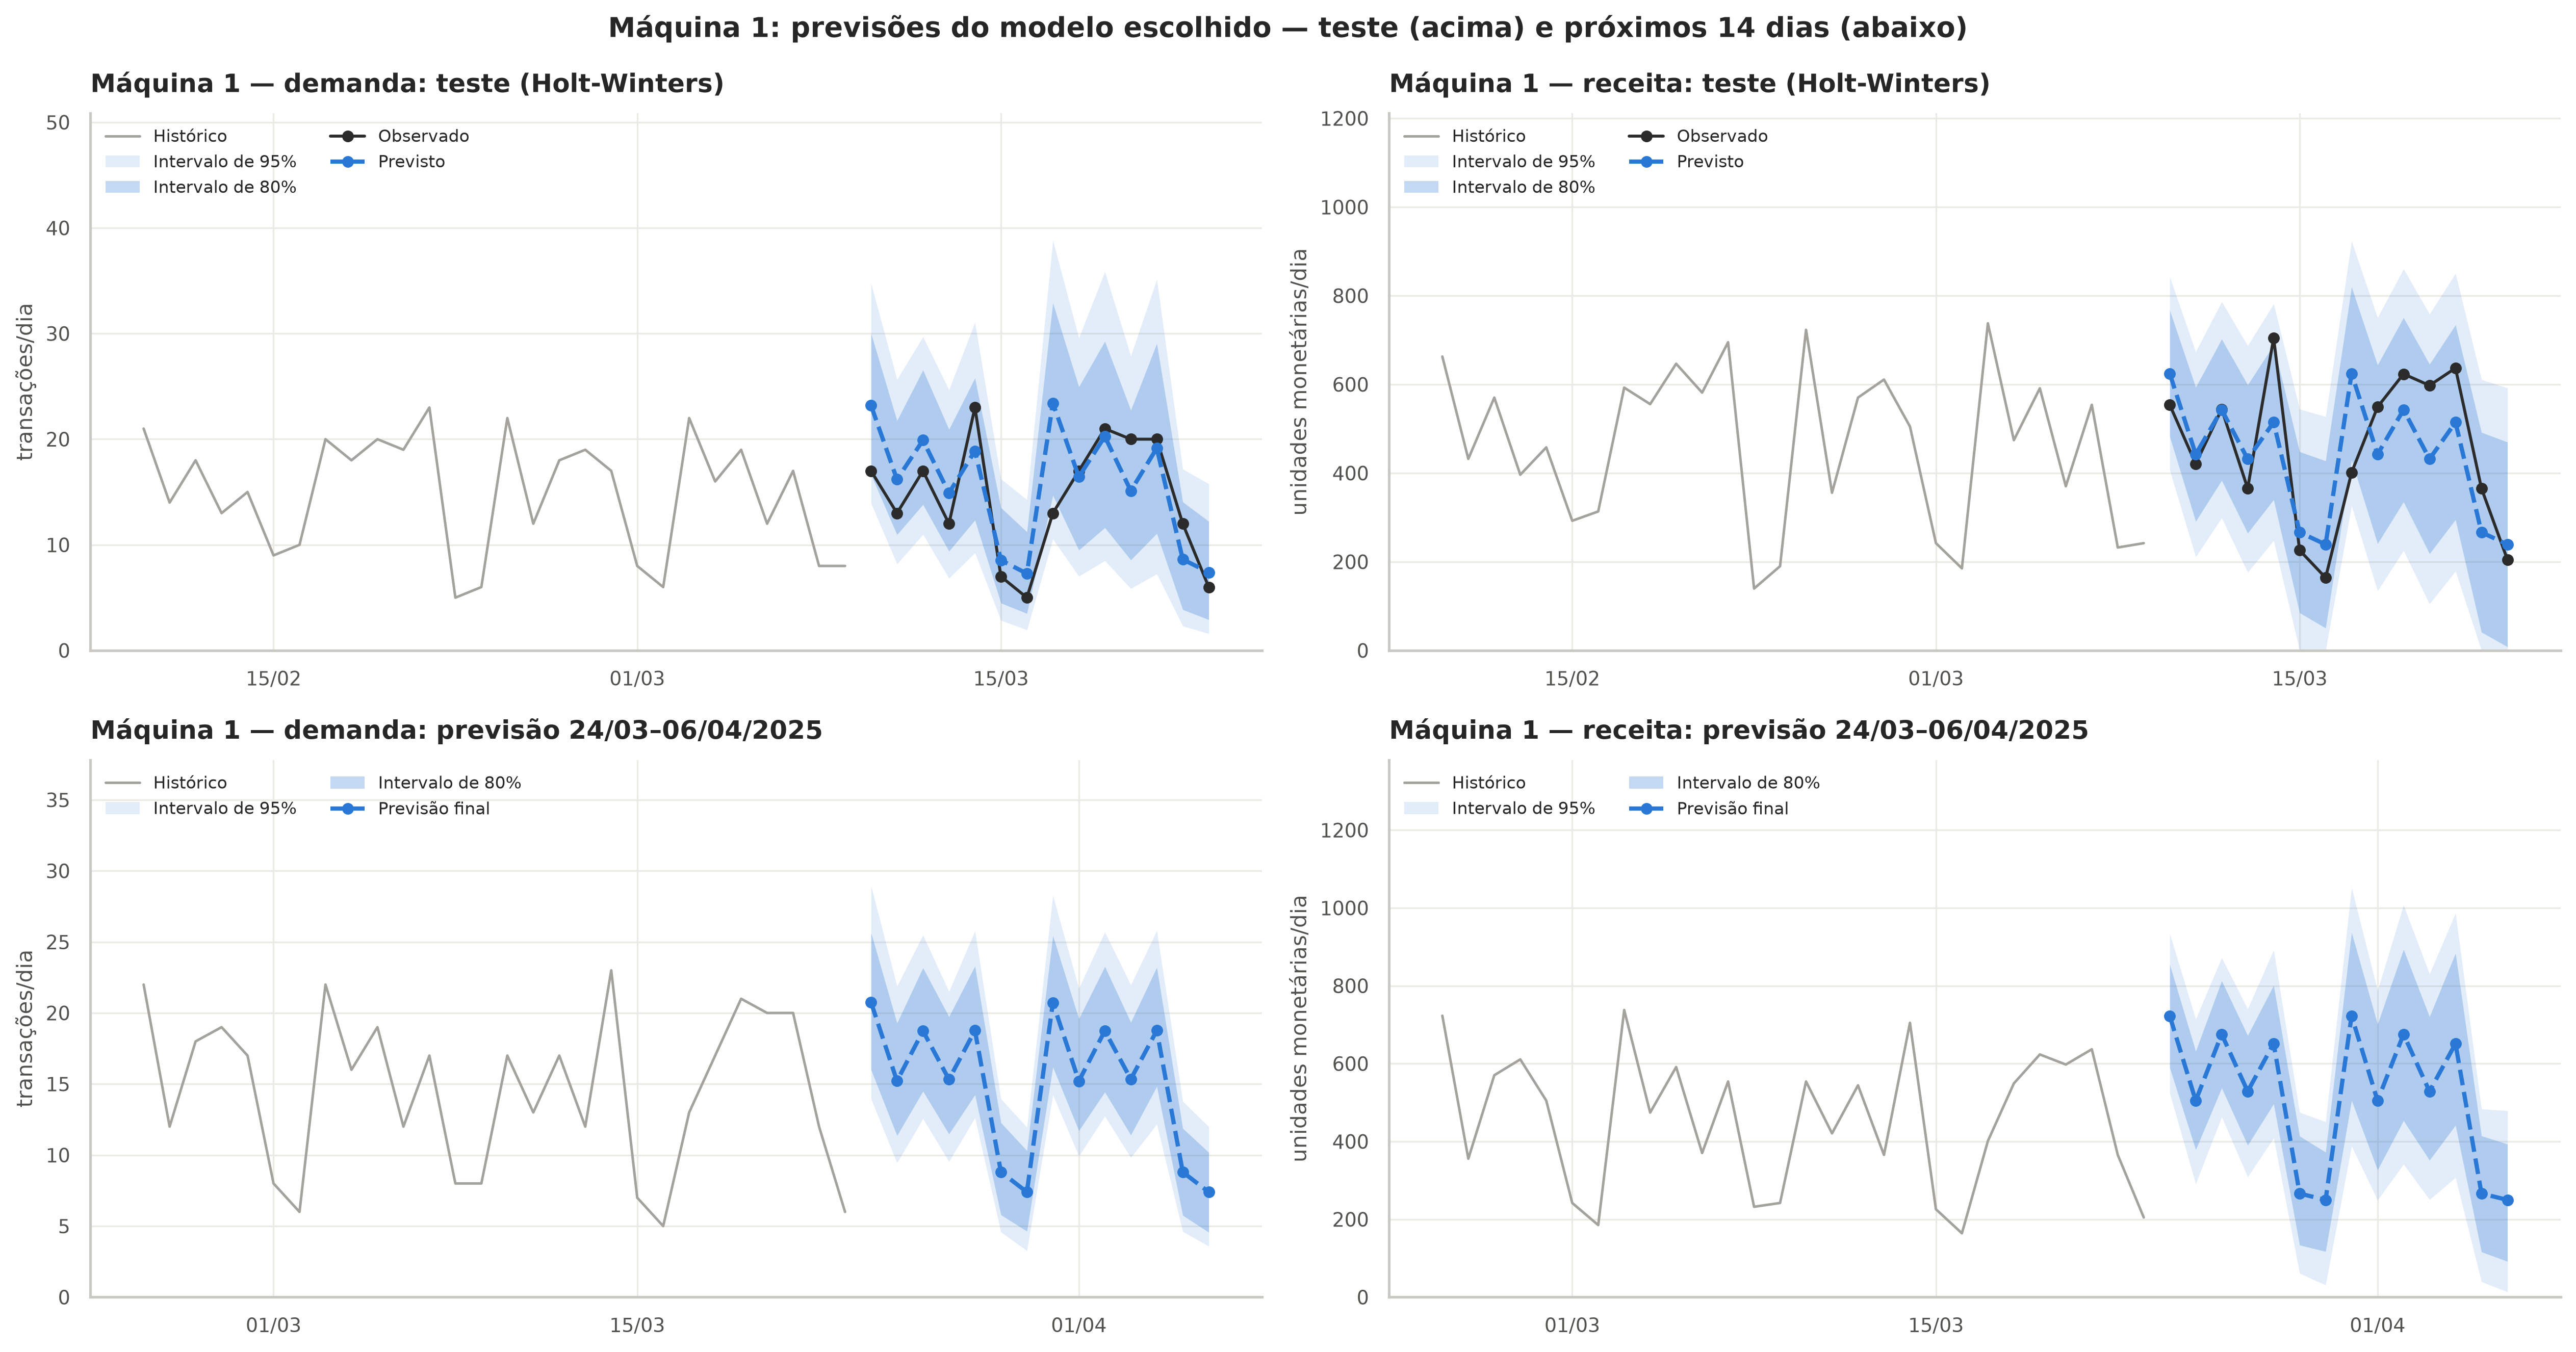

previsto             li_80             ls_80          
            mean       sum    mean       sum    mean       sum
alvo                                                          
demanda   15.000   210.000  11.200   156.900  19.000   266.600
receita  514.100 7,197.900 352.200 4,930.200 678.700 9,501.600

**machine_2**

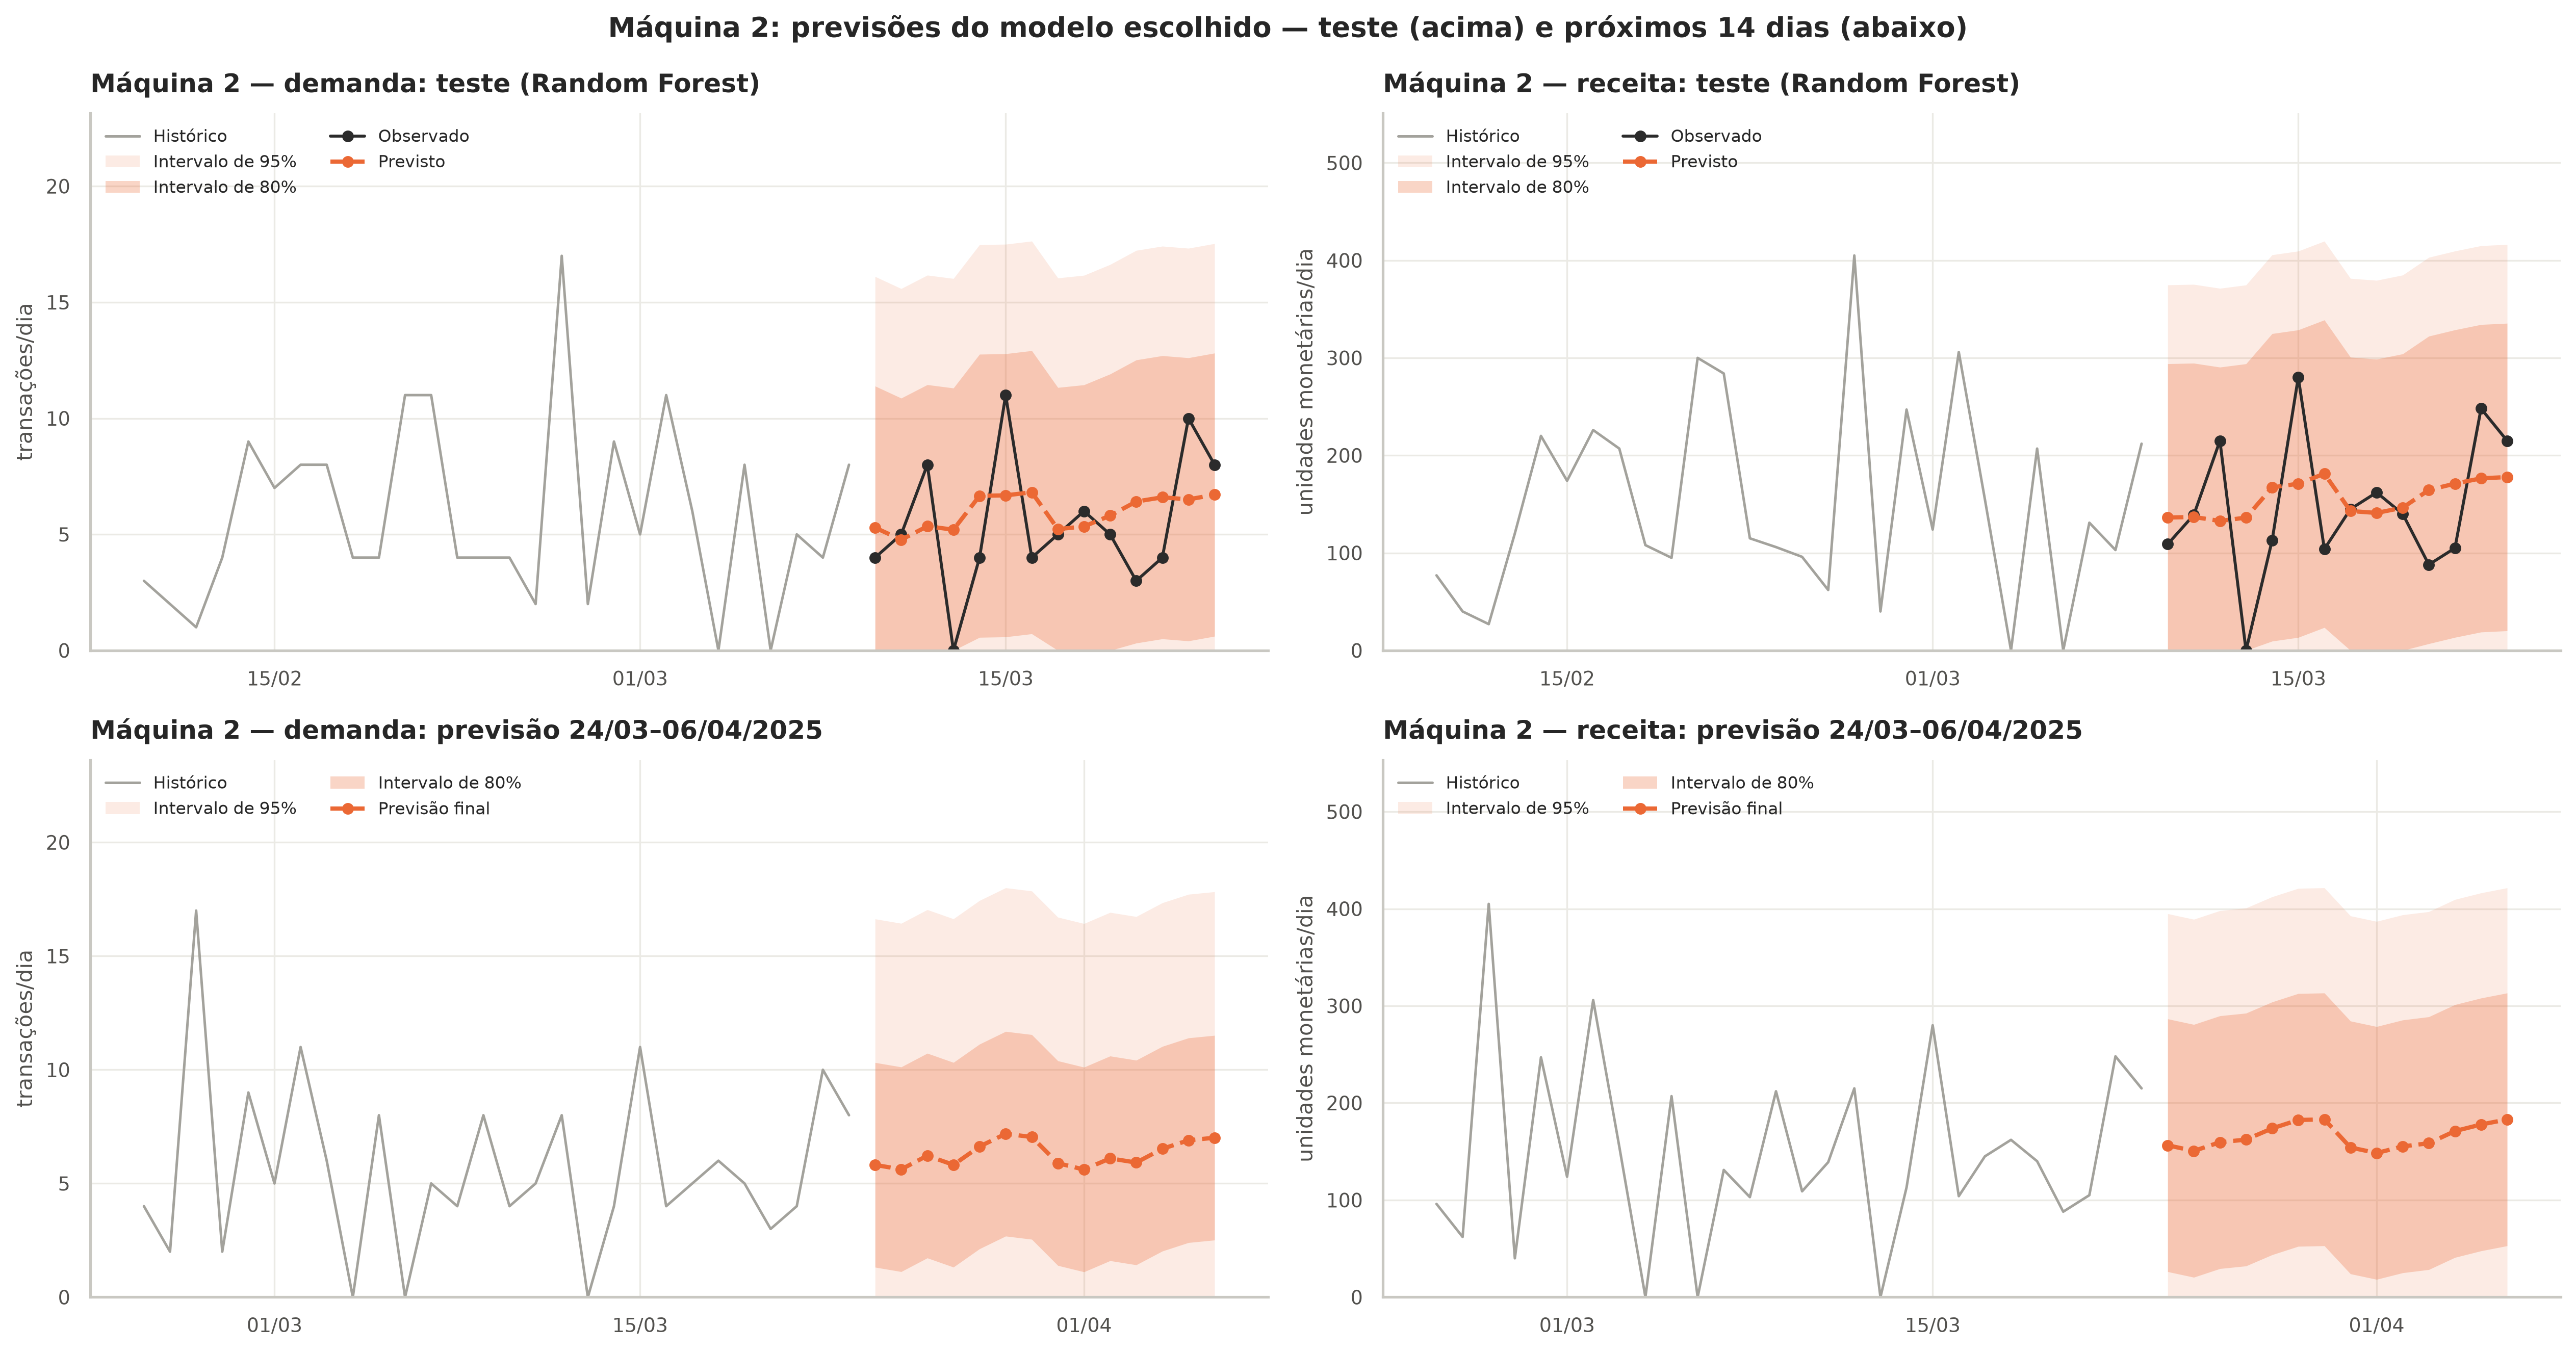

previsto            li_80           ls_80          
            mean       sum   mean     sum    mean       sum
alvo                                                       
demanda    6.300    88.300  1.800  25.300  10.800   151.300
receita  165.400 2,316.200 35.300 493.800 295.600 4,138.600

**total**

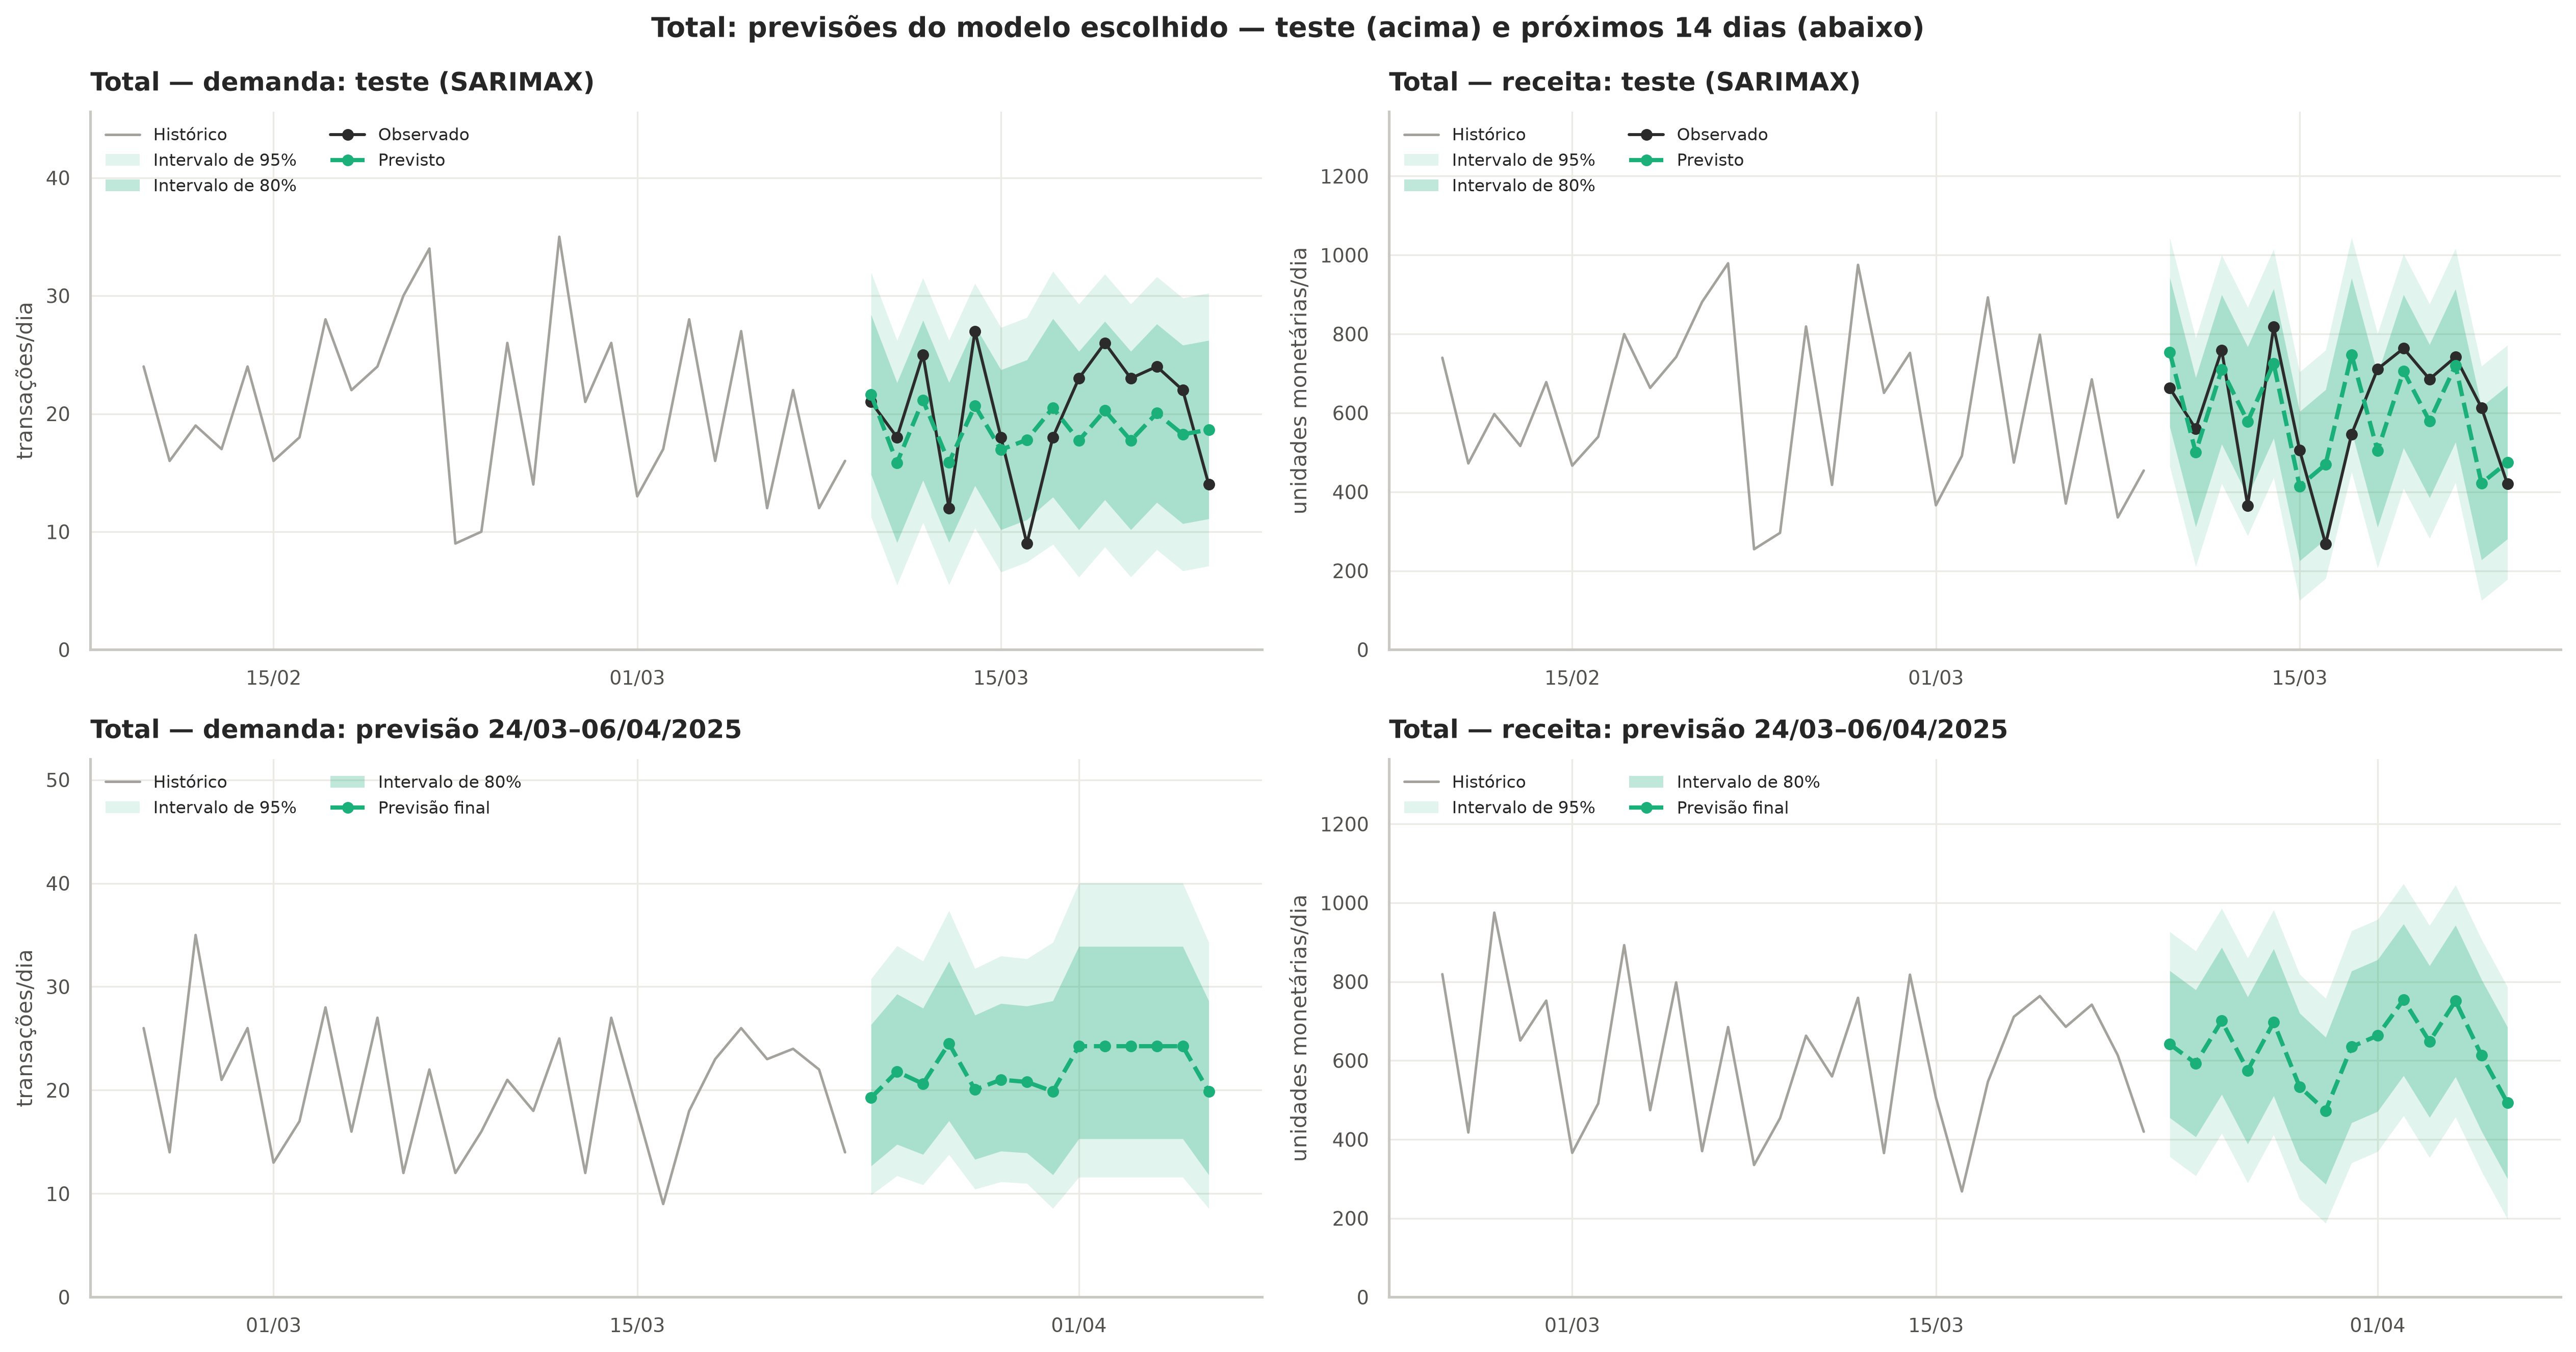

previsto             li_80             ls_80           
            mean       sum    mean       sum    mean        sum
alvo                                                           
demanda   22.100   309.100  14.300   199.800  30.500    426.500
receita  626.500 8,771.200 437.100 6,119.000 816.000 11,423.300

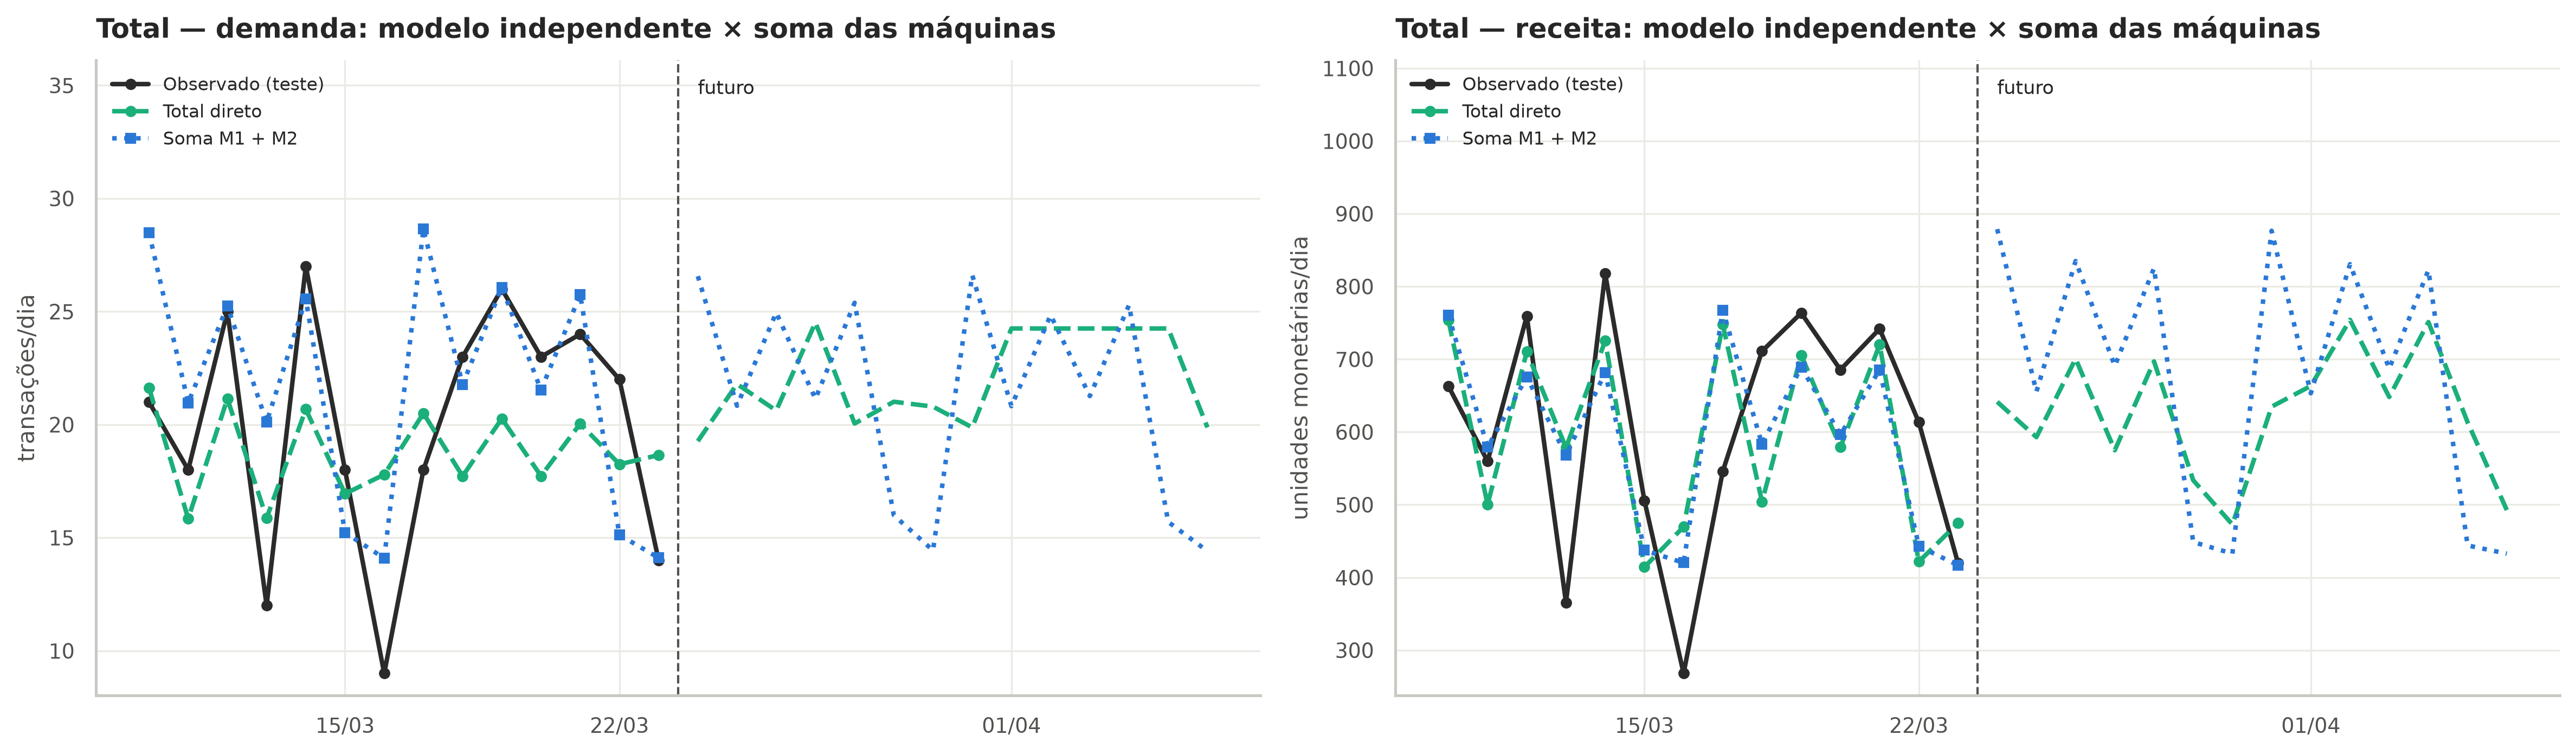

,série,alvo,modelo,especificação,treino,horizonte,previsão,hash_config,hash_dados,arquivo_modelo,gerado_em
0,Máquina 1,demanda,Holt-Winters,"ETS(A,Ad,M) · últimas 8 semanas · raiz (Anscombe)","['2025-01-27', '2025-03-23']",14,"['2025-03-24', '2025-04-06']",6da152eedcb9,{'index_1.csv': {'sha256': '2a600445a1836da436...,machine_1_demanda.joblib,2026-11-10 19:07:10
1,Máquina 1,receita,Holt-Winters,"ETS(A,N,M) · últimas 8 semanas · nenhuma","['2025-01-27', '2025-03-23']",14,"['2025-03-24', '2025-04-06']",6da152eedcb9,{'index_1.csv': {'sha256': '2a600445a1836da436...,machine_1_receita.joblib,2026-11-10 19:07:11
2,Máquina 2,demanda,Random Forest,"max_depth=8, min_samples_leaf=5, max_features=...","['2025-02-08', '2025-03-23']",14,"['2025-03-24', '2025-04-06']",6da152eedcb9,{'index_1.csv': {'sha256': '2a600445a1836da436...,machine_2_demanda.joblib,2026-11-10 19:07:33
3,Máquina 2,receita,Random Forest,"max_depth=8, min_samples_leaf=5, max_features=...","['2025-02-08', '2025-03-23']",14,"['2025-03-24', '2025-04-06']",6da152eedcb9,{'index_1.csv': {'sha256': '2a600445a1836da436...,machine_2_receita.joblib,2026-11-10 19:07:51
4,Total,demanda,SARIMAX,"SARIMA(0,1,1)(0,0,1)[7] + [maquinas_ativas, da...","['2025-01-27', '2025-03-23']",14,"['2025-03-24', '2025-04-06']",6da152eedcb9,{'index_1.csv': {'sha256': '2a600445a1836da436...,total_demanda.joblib,2026-11-10 19:07:58
5,Total,receita,SARIMAX,"SARIMA(0,1,1)(1,0,1)[7] + [maquinas_ativas, fe...","['2024-12-02', '2025-03-23']",14,"['2025-03-24', '2025-04-06']",6da152eedcb9,{'index_1.csv': {'sha256': '2a600445a1836da436...,total_receita.joblib,2026-11-10 19:08:09


In [9]:
for pasta in ["machine_1", "machine_2", "total"]:
    display(Markdown(f"**{pasta}**"))
    display(Image(filename=str(RAIZ / f"reports/forecasts/{pasta}/previsoes_modelo_escolhido.png"), width=1100))
    fut = pd.read_csv(RAIZ / f"reports/forecasts/{pasta}/previsao_futura_14_dias.csv")
    display(fut.groupby("alvo")[["previsto", "li_80", "ls_80"]].agg(["mean", "sum"]).round(1))
display(Image(filename=str(RAIZ / "reports/forecasts/total/total_direto_vs_soma_maquinas.png"), width=1100))
display(pd.read_csv(RAIZ / "models/registro_modelos.csv"))

## 9. Conclusões

1. **Os candidatos superam o naive de forma consistente.** No Total, a vantagem é estatisticamente significativa. Na M1, os ganhos de ~20–24% ainda não se distinguem do acaso com 11 blocos.
2. **A Média 4 semanas é um adversário difícil.** Nenhum modelo a supera com significância, o que é coerente com o piso de ruído alto: boa parte do erro é irredutível.
3. **Mudanças de regime são o principal risco.** Todos os modelos pioram em torno da quebra de 2025; o Holt-Winters é o mais robusto.
4. **A Máquina 2 não tem histórico** para estrutura temporal: a previsão adequada é um nível com intervalo largo, a ser revisto com 2–3 meses de dados.
5. **Precisão realista para a operação:** ~20% do volume na M1 e no Total e ~40% na M2, com intervalos que cobrem a maior parte dos dias.